# Flux: NEE, GPP and RECO of the LI-7500 years against independent estimates

# About this notebook

The open-path LI-7500 (`IRGA75`) years 2005-2009 of this product are close to carbon neutral or a
net source of CO2, while the LI-7200 (`IRGA72`) years from 2016 are a net sink. For the same forest
and the years 2005-2009, Etzold et al. (2011, Ecosystems 14:1289-1309) report carbon fluxes that
do not come from eddy covariance: net ecosystem production (`NEP`) from two forest inventories,
soil respiration (`SR`) and its heterotrophic part (`Rh`) from soil chambers, net primary
production (`NPP`) from allometry, stem growth from dendrometers, and soil carbon change from a
soil model. They also report their own eddy-covariance `NEE`, `GPP` and ecosystem respiration
(`TER`).

This notebook compares the annual `NEE`, `GPP` and `RECO` of this product with these values, over
the periods each of them covers, and compares the nighttime `NEE` of this product with the
temperature response of soil respiration in their Fig. 4. It asks whether the early years are
consistent with the independent constraints and, where they are not, whether the difference lies
in the respiration or in the gross uptake. It computes no product.

**Which run is shown.** The notebook reads the outputs of the flux chain as they are on disk, so a
rerun of the chain refreshes every number below. The modification time of each input file is
printed under *Load data*; the numbers belong to the run of that date. The `IRGA75` run shown may
still use the stricter tests of negative nighttime values; the test run `T2` with the relaxed tests
covers 2004-2006 and is shown beside it where it exists.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. `GPP`, `RECO`,
`SR`, `Rh`, `NPP` and `NEP` are positive. `NEP` is a net gain of carbon by the ecosystem, so it
corresponds to `-NEE`. Half-hourly values are in µmol CO2 m⁻² s⁻¹ and annual sums in gC m⁻² yr⁻¹
(1 µmol m⁻² s⁻¹ over 30 minutes is 0.0216 gC m⁻²). The published values are in Mg C ha⁻¹ yr⁻¹ and
are converted with 1 Mg C ha⁻¹ = 100 gC m⁻².

**Columns used**

- This product, `IRGA75` (`30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`)
  and `IRGA72` (`.../IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`):
  - `NEE_L3.1_L3.3_CUT_{16,50,84}_QCF_gfXG` — `NEE` after all quality tests, filtered at the
    three USTAR thresholds and gap-filled with XGBoost. `CUT_50` is the main series
  - `NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC` — its random uncertainty per half-hour
  - `NEE_L3.1_L3.3_CUT_50_QCF` — the measured records of the main series, before gap-filling
  - `GPP_NT_OF_CUT_50`, `RECO_NT_OF_CUT_50` — nighttime partitioning (Reichstein et al. 2005, as
    in ONEFlux): respiration fitted to measured nighttime `NEE` against air temperature, with one
    temperature sensitivity `E0_NT_OF_CUT_50` per year; `GPP = RECO - NEE`
  - `GPP_DT_OF_CUT_50`, `RECO_DT_OF_CUT_50` — daytime partitioning (Lasslop et al. 2010, as in
    ONEFlux): a light response fitted to daytime `NEE`. `GPP` and `RECO` are modelled separately,
    so `RECO - GPP` is not exactly `NEE`
  - `NIGHTTIME` — the night flag of this product
- The test run `T2` (`.../IRGA75/T2_FPPC_IRGA75_NEE_OPCO_2004-2006`), with the relaxed tests of
  negative nighttime values: the same three `NEE` columns, 2004-2006
- Soil temperature (`10_METEO/30_PRODUCTS/10_METEO_TS_FF1_2004-2025`):
  `TS_FF1_0.05_HOMOGENIZED_GAPFILLED` at 0.05 m, used only where its `METHOD` flag is `1` or `2`
  (measured)

**Periods.** The published values cover different periods: the eddy-covariance values 2005-2009,
`NEP`, `NPP` and soil respiration 2006-2009 (between the inventories of 2005 and 2009), `Rh` from
chambers 2007-2008 and stem growth 2006-2007. Each comparison uses the mean of this product over
the same years.

**Footprint and plot.** The biometric values describe an inventory area of 1.48 ha and 16 soil
respiration plots within the flux footprint (Etzold et al. 2011, Table 3 and p. 1294). The flux
footprint is larger and covers a managed and an unmanaged part of the forest in about equal
shares.

# Main findings

The numbers behind each point are in the tables below.

- **Net uptake.** In 2006-2009 the net uptake of this product (`-NEE`) lies far below every
  biometric estimate of `NEP`, for all three USTAR scenarios and also with the relaxed tests of the
  test run. The biometric estimates agree with the eddy-covariance `NEE` of the 2011 study.
- **Respiration.** Annual ecosystem respiration from both partitionings exceeds the measured soil
  respiration, as it must, with a soil share inside the range the 2011 study allows, and `RECO`
  lies within the stated uncertainty of their `TER`.
- **Nights against soil temperature.** Measured nighttime `NEE` responds much less to soil
  temperature than the chamber soil respiration: on cold nights it is several times the soil
  respiration, on the warmest nights about equal to it. This holds for both analysers. On cold
  nights the LI-7500 is somewhat higher than the LI-7200 at the same soil temperature, but this
  accounts for only a small part of the difference to the biometric `NEP`.
- **Gross uptake.** `GPP` from both partitionings is well below the `GPP` of the 2011 study, and
  below the `GPP` implied by the biometric `NPP` and a typical ratio of `NPP` to `GPP`. The ratio
  of `NPP` to `GPP` implied by this product is at the high end of what is reported for forests.
- **Where the difference lies.** Most of the difference to the 2011 study is in `GPP`, that
  is, in the daytime flux, not in the respiration. This agrees with the finding of the comparison
  notebook that the self-heating correction of this product adds much more by day than the
  correction used in 2011, and that the summer daytime uptake of 2005-2007 is low.
- **Implied heterotrophic respiration.** For `NEP = -NEE`, the biometric `NPP` would have to be
  balanced by a heterotrophic respiration well above the chamber and model estimates and close to
  the whole soil respiration. This is not plausible.
- **The LI-7200 years** also show less net uptake than the biometric `NEP` of 2006-2009, with
  more `GPP` than the LI-7500 years. The biometric values do not cover these years, so this is a
  comparison across a decade, not a check.

</br>

# Settings

In [1]:
# This product. The flux chain's outputs are read as they are on disk, so a rerun of the chain
# refreshes every number in this notebook.
DATADIR = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow"
FILE_NEE75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
FILE_NEE75_T2 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\T2_FPPC_IRGA75_NEE_OPCO_2004-2006.parquet"
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_TS = r"10_METEO\30_PRODUCTS\10_METEO_TS_FF1_2004-2025.parquet"

SCENARIOS = {'CUT_16': 'NEE_L3.1_L3.3_CUT_16_QCF_gfXG',
             'CUT_50': 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG',
             'CUT_84': 'NEE_L3.1_L3.3_CUT_84_QCF_gfXG'}
varname = SCENARIOS['CUT_50']  # the main series
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # 0 measured, 1 gap-filled
varname_meas = 'NEE_L3.1_L3.3_CUT_50_QCF'  # measured records of the main series
randunc = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC'
PARTITIONING = {'GPP_NT': 'GPP_NT_OF_CUT_50', 'RECO_NT': 'RECO_NT_OF_CUT_50',
                'GPP_DT': 'GPP_DT_OF_CUT_50', 'RECO_DT': 'RECO_DT_OF_CUT_50'}
E0_NT = 'E0_NT_OF_CUT_50'  # one temperature sensitivity per year, vs air temperature, Tref 15 degC
NIGHTTIME = 'NIGHTTIME'
TS = 'TS_FF1_0.05_HOMOGENIZED_GAPFILLED'  # soil temperature at 0.05 m, degC
TS_METHOD = 'FLAG_TS_FF1_0.05_HOMOGENIZED_GAPFILLED_METHOD'
TS_MEASURED = [1, 2]  # METHOD codes of measured values; docs/Meteo_Data_TS.md

# Periods.
YEARS75 = (2005, 2009)  # the LI-7500 years of the 2011 study
YEARS72 = (2016, 2025)  # full LI-7200 years of this product, the reference
FIG4_YEARS = (2006, 2009)  # the years of the soil respiration in Fig. 4 of the 2011 study

# Published values of Etzold et al. 2011 (Ecosystems 14:1289-1309) for Laegeren, declared here
# because they are in no data file. Values as printed, in Mg C ha-1 yr-1, made positive for the
# gross fluxes; they are converted to gC m-2 yr-1 below. 'unc' is a symmetric uncertainty,
# 'range' an asymmetric one, both as printed. The kind of uncertainty is given per row
# (Table 5 footnote and p. 1296-1298: maximum error margins for NPP components, 95 % confidence
# intervals for SR, Rh and soil C, gap-filling plus random error for NEE, and a maximum error of
# 25 % for the annual sums of TER and GPP).
MG_HA_TO_G_M2 = 100  # 1 Mg C ha-1 = 100 gC m-2
PUBLISHED = [
    # key, label, value, unc, range, first year, last year, source, method, kind of uncertainty
    ('NEE_EC', "NEE, eddy covariance", -4.15, 0.56, None, 2005, 2009, "Table 4",
     "EC, LI-7500", "gap-filling and random error"),
    ('NEE_EC_0609', "NEE, eddy covariance", -4.35, 0.56, None, 2006, 2009, "Table 5",
     "EC, LI-7500", "gap-filling and random error"),
    ('GPP_EC', "GPP, eddy covariance", 18.30, 4.48, None, 2005, 2009, "Table 4",
     "EC, partitioned", "maximum error, 25 %"),
    ('TER_EC', "TER, eddy covariance", 13.83, 3.38, None, 2005, 2009, "Table 4",
     "EC, nighttime temperature response", "maximum error, 25 %"),
    ('SR', "soil respiration SR", 8.90, 0.46, None, 2006, 2009, "Table 4",
     "chambers, 17 manual and 1 automated", "95 % confidence interval"),
    ('RH_CH', "heterotrophic soil respiration Rh", 5.07, 0.48, None, 2007, 2008, "Table 4",
     "chambers, root exclusion", "95 % confidence interval"),
    ('RH_MOD', "heterotrophic respiration Rh (modelled)", 4.55, 0.27, None, 2006, 2009, "Table 5",
     "Yasso07 soil model", "95 % confidence interval"),
    ('SOILC', "soil carbon gain", 0.22, 0.17, None, 2006, 2009, "Table 5",
     "Yasso07 soil model", "95 % confidence interval"),
    ('DRC', "stem growth DR_C", 3.75, 1.13, None, 2006, 2007, "Table 4",
     "point dendrometers", "as printed"),
    ('NPP', "NPP", 7.63, 0.29, None, 2006, 2009, "Table 5",
     "allometry, litter traps, root cores", "maximum error margin"),
    ('NPP_AG', "NPP aboveground (trees)", 6.11, 0.19, None, 2006, 2009, "Table 5",
     "allometry, litter traps", "maximum error margin"),
    ('NPP_WOOD', "NPP trunk + branches and twigs", 2.40 + 1.29, 0.05 + 0.03, None, 2006, 2009,
     "Table 5 (2.40 + 1.29)", "allometry", "maximum error margin, summed"),
    ('NPP_US', "NPP understory", 0.40, None, (0.33, 0.43), 2006, 2009, "Table 5",
     "earlier measurements", "range"),
    ('NPP_BG', "NPP belowground", 1.10, 0.02, None, 2006, 2009, "Table 5",
     "allometry, root cores", "maximum error margin"),
    ('NEP_STAR', "NEP* (NPP - Rh)", 3.07, None, (2.96, 3.19), 2006, 2009, "Table 5",
     "allometry and soil model", "range"),
    ('NEP_DC', "NEP as change in C pools (ΔC)", 4.29, None, (4.14, 4.44), 2006, 2009, "Table 5",
     "inventories 2005 and 2009", "range"),
    ('NEP_BM', "NEP_BM (pools 2009 minus 2006)", 4.34, None, (4.18, 4.50), 2006, 2009, "Table 5",
     "inventories", "range"),
    ('NEP_BEF', "NEP_BEF (expansion factors)", 5.14, None, (5.03, 5.25), 2006, 2009, "Table 5",
     "biomass expansion factors", "range"),
]
# The range of the annual NEE of 2005-2009, gC m-2 yr-1; p. 1301.
ETZOLD_NEE_YEARS = (-662, -366)
# The biometric NEP estimates that span the plausible range: NEP* (lowest) to NEP_BEF (highest),
# p. 1299. NEP_BEF is regarded by the authors as the least reliable (p. 1296, 1303-1304).
NEP_KEYS = ['NEP_STAR', 'NEP_DC', 'NEP_BM', 'NEP_BEF']
# Soil respiration temperature response, p. 1299: Lloyd-Taylor reference respiration of the
# automated and the manual chambers in 2008 and 2009, "for a temperature range between 5 and
# 10 degC". The reference temperature is not stated; the curves of Fig. 4 pass through these
# values at about 9-10 degC (section 3), so 10 degC is assumed.
SR_RREF = {'SR automated': 1.91, 'SR manual': 2.22}  # umol m-2 s-1
SR_RREF_YEARS = (2008, 2009)
# Ratios quoted by the 2011 study, p. 1303-1304: TER/GPP from NEP_BEF at Laegeren, and the
# reference value for European forests the study takes from Luyssaert et al. 2009 (as cited
# there).
TER_GPP_NEPBEF = 0.63
TER_GPP_EUROPE = 0.74
# Ratio of NPP to GPP (carbon-use efficiency) of forests, Waring et al. 1998 (Tree Physiology
# 18:129-134): 0.47 +- 0.04. A literature value, not from the 2011 study.
CUE_FOREST = (0.47, 0.04)

# Soil respiration against soil temperature, read from Fig. 4 (p. 1301) of the 2011 study: the
# fitted Lloyd-Taylor curves, A for the automated chamber (daily means, four curves 2006-2009) and
# C for the manual chambers (campaign means). The axes were calibrated on the tick marks of a
# 400 dpi rendering and the black curve pixels were located per degree. 'central' is the solid
# curve (2007), 'low' and 'high' the envelope of the four curves. Reading accuracy about
# +-0.1 umol m-2 s-1 for a single curve; the envelope is less certain (+-0.2), because the dashed
# curves have gaps. The soil depth of the temperature is not stated in the paper.
FIG4_T = [2, 4, 6, 8, 10, 12, 14, 16, 18]  # soil temperature, degC
FIG4 = {
    'SR automated': {'central': [0.65, 0.90, 1.18, 1.54, 1.97, 2.50, 3.06, 3.66, 4.23],
                     'low':     [0.48, 0.80, 1.00, 1.30, 1.85, 2.45, 2.85, 3.40, 4.20],
                     'high':    [0.80, 1.10, 1.40, 2.00, 2.60, 3.30, 4.30, 5.30, 6.55]},
    'SR manual':    {'central': [0.88, 1.11, 1.40, 1.85, 2.37, 2.90, 3.60, 4.30, 5.02],
                     'low':     [0.75, 0.85, 1.08, 1.60, 2.20, 2.80, 3.50, 4.20, 4.95],
                     'high':    [0.95, 1.15, 1.45, 1.90, 2.45, 3.00, 4.15, 4.40, 5.10]},
}
FIG4_ACCURACY = 0.1  # umol m-2 s-1, single curve

# Lloyd-Taylor function as in the partitioning of this product (T0 -46.02 degC). The soil
# comparison uses a reference temperature of 10 degC; the partitioning of this product uses 15.
T0_LT = -46.02
TREF_SOIL = 10.0
TS_BIN_HALFWIDTH = 1.0  # degC; the bins are centred on FIG4_T

units = "µmol m-2 s-1"
units_sum = "gC m-2 yr-1"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2
COLORS = {'IRGA75': '#1E88E5', 'IRGA72': '#43A047', 'study2011': '#212121', 'SR': '#8D6E63',
          'GPP': '#2E7D32', 'RECO': '#C62828', 'NEP': '#6A1B9A', 'T2': '#90CAF9'}

# Imports

In [2]:
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.0f}", subset=None, cmap=None, axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and an optional colour scale.

    The caption is printed above the table. `center` puts the midpoint of the colour scale at
    zero; `axis=None` scales the colours across the whole table (or `subset`). The colour scale
    sets a text colour per cell, so the numbers stay readable in light and dark pages.
    """
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data[numeric]
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def to_gc(s):
    """Half-hourly flux in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def per_year(s, how=to_gc):
    """One value per calendar year, indexed by the year number."""
    out = s.groupby(s.index.year).agg(how)
    out.index.name = 'YEAR'
    return out


def period_mean(annual, years):
    """Mean of a table of annual values over the calendar years `years` = (first, last)."""
    return annual.loc[years[0]:years[1]].mean()


def pub(key):
    """A published value in gC m-2 yr-1 with its lower and upper bound."""
    return published.loc[key, 'value'], published.loc[key, 'low'], published.loc[key, 'high']


def lloyd_taylor(t, rref, e0, tref=TREF_SOIL):
    """Lloyd-Taylor respiration at temperature `t` (degC); `rref` is the value at `tref`."""
    return rref * np.exp(e0 * (1.0 / (tref - T0_LT) - 1.0 / (np.asarray(t, dtype=float) - T0_LT)))


def fit_lloyd_taylor(t, r, tref=TREF_SOIL):
    """Least-squares fit of `lloyd_taylor` to temperatures `t` and fluxes `r`.

    Returns (rref, e0, rref_se, e0_se, n). Unweighted, so a fit to half-hours describes the mean
    response, a fit to curve readings the curve.
    """
    t, r = np.asarray(t, dtype=float), np.asarray(r, dtype=float)
    ok = np.isfinite(t) & np.isfinite(r)
    p, cov = curve_fit(lambda x, a, b: lloyd_taylor(x, a, b, tref), t[ok], r[ok], p0=(2.0, 200.0),
                       maxfev=20000)
    se = np.sqrt(np.diag(cov))
    return p[0], p[1], se[0], se[1], int(ok.sum())


def q10(e0, t_low=5.0, t_high=15.0):
    """The Q10 that a Lloyd-Taylor E0 implies between `t_low` and `t_high` degC."""
    return np.exp(e0 * (1.0 / (t_low - T0_LT) - 1.0 / (t_high - T0_LT))) ** (10.0 / (t_high - t_low))


def verdict(x, low, high):
    """'within', 'below' or 'above' the published range [low, high]."""
    if pd.isna(x) or pd.isna(low) or pd.isna(high):
        return "-"
    return "within" if low <= x <= high else ("below" if x < low else "above")

</br>

# Load data

In [4]:
_files = {'IRGA75 NEE (05)': Path(DATADIR) / FILE_NEE75,
          'IRGA75 NEE, test run T2': Path(DATADIR) / FILE_NEE75_T2,
          'IRGA72 NEE (05)': Path(DATADIR) / FILE_NEE72,
          'soil temperature (10_METEO_TS_FF1)': Path(DATADIR) / FILE_TS}
_cols = [*SCENARIOS.values(), flagname, varname_meas, randunc, *PARTITIONING.values(), E0_NT,
         NIGHTTIME]
nee75 = pd.read_parquet(_files['IRGA75 NEE (05)'], columns=_cols)
nee72 = pd.read_parquet(_files['IRGA72 NEE (05)'], columns=_cols)
ts = pd.read_parquet(_files['soil temperature (10_METEO_TS_FF1)'], columns=[TS, TS_METHOD])
# The test run is optional: it exists only while the relaxed tests are being evaluated.
HAS_T2 = _files['IRGA75 NEE, test run T2'].is_file()
t2 = (pd.read_parquet(_files['IRGA75 NEE, test run T2'], columns=list(SCENARIOS.values()))
      if HAS_T2 else None)
for _df in (nee75, nee72, ts, t2):
    if _df is not None:
        _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
        _df.index.name = 'TIMESTAMP_MIDDLE'
print(f"test run T2 present: {HAS_T2}")

test run T2 present: True


## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" if p.is_file() else "missing"
                 for p in _files.values()],
    'records': [len(nee75), len(t2) if HAS_T2 else np.nan, len(nee72), len(ts)],
}, index=list(_files))
display(styled(_inputs, caption="the input files with their modification time. The numbers in this "
                                "notebook belong to the runs of these dates",
               fmt="{:,.0f}"))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified,records
IRGA75 NEE (05),05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-30 19:27,"245,472"
"IRGA75 NEE, test run T2",T2_FPPC_IRGA75_NEE_OPCO_2004-2006.parquet,2026-10-30 14:14,"52,608"
IRGA72 NEE (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-30 19:02,"188,448"
soil temperature (10_METEO_TS_FF1),10_METEO_TS_FF1_2004-2025.parquet,2026-07-30 15:09,"373,728"


In [6]:
# The frames used below: the LI-7500 years of the 2011 study, the LI-7200 reference years, each
# joined with the soil temperature where it was measured.
_ts = ts[TS].where(ts[TS_METHOD].isin(TS_MEASURED))
d75 = nee75.loc[str(YEARS75[0]):str(YEARS75[1])].join(_ts)
d72 = nee72.loc[str(YEARS72[0]):str(YEARS72[1])].join(_ts)
for _d in (d75, d72):
    _d['night'] = _d[NIGHTTIME].eq(1)
    _d['meas'] = _d[flagname].eq(0)
print(f"LI-7500 frame: {d75.index[0]} -> {d75.index[-1]} ({len(d75):,} records)")
print(f"LI-7200 frame: {d72.index[0]} -> {d72.index[-1]} ({len(d72):,} records)")

LI-7500 frame: 2005-01-01 00:15:00 -> 2009-12-31 23:45:00 (87,648 records)
LI-7200 frame: 2016-01-01 00:15:00 -> 2025-12-31 23:45:00 (175,344 records)


## Integrity checks

In [7]:
# Everything below assumes complete 30MIN records without duplicates, complete main series and
# partitioning in the years used, the documented relation of the nighttime partitioning
# (GPP = RECO - NEE), and a measured soil temperature in most of the years used.
_issues = []
for _name, _df in (('IRGA75 05', nee75), ('IRGA72 05', nee72), ('TS', ts), ('T2', t2)):
    if _df is None:
        continue
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
    if not (_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
        _issues.append(f"{_name}: index gaps")
for _name, _d, _y in (('IRGA75', d75, YEARS75), ('IRGA72', d72, YEARS72)):
    _expected = pd.date_range(f"{_y[0]}-01-01 00:15", f"{_y[1]}-12-31 23:45", freq='30min')
    if not _d.index.equals(_expected):
        _issues.append(f"{_name}: the frame does not cover every half-hour of {_y[0]}-{_y[1]}")
    for _c in [*SCENARIOS.values(), *PARTITIONING.values(), randunc]:
        if _d[_c].isna().any():
            _issues.append(f"{_name}: {_c} has {int(_d[_c].isna().sum())} missing values")
    if (_d[[PARTITIONING['RECO_NT'], PARTITIONING['RECO_DT']]] < 0).any().any():
        _issues.append(f"{_name}: negative RECO")
    _dev = (_d[PARTITIONING['GPP_NT']] - (_d[PARTITIONING['RECO_NT']] - _d[varname])).abs().max()
    if _dev > 1e-3:
        _issues.append(f"{_name}: GPP_NT is not RECO_NT - NEE (max deviation {_dev:.3g})")
    if (_d[flagname].eq(0) != _d[varname_meas].notna()).any():
        _issues.append(f"{_name}: fill flag and measured records disagree")
    if _d[E0_NT].groupby(_d.index.year).nunique().max() > 1:
        _issues.append(f"{_name}: more than one E0 per year")
    _ts_cov = _d[TS].notna().groupby(_d.index.year).mean()
    print(f"{_name}: measured soil temperature per year (%): "
          f"{(_ts_cov * 100).round(0).astype(int).to_dict()}")
if HAS_T2 and t2.loc[str(YEARS75[0]):].isna().any().any():
    _issues.append("T2: missing values")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

IRGA75: measured soil temperature per year (%): {2005: 100, 2006: 97, 2007: 82, 2008: 100, 2009: 75}
IRGA72: measured soil temperature per year (%): {2016: 100, 2017: 97, 2018: 98, 2019: 100, 2020: 100, 2021: 98, 2022: 97, 2023: 100, 2024: 99, 2025: 100}
Integrity checks passed.


</br>

# 1. The published estimates

All values are from Etzold et al. (2011) for the Lägeren forest, converted to gC m⁻² yr⁻¹. The
biometric `NEP` estimates differ in what they include (Table 2 and p. 1296 of the study):

- `NEP*` is `NPP` minus heterotrophic respiration from the soil model, the most complete
  estimate. The study notes that it likely underestimates `NEP`, because it misses the carbon
  passed to mycorrhiza and root exudates.
- `ΔC` is the increment of woody biomass and soil carbon between the inventories of 2005 and 2009.
- `NEP_BM` is the change of all woody and non-woody pools between 2006 and 2009.
- `NEP_BEF` uses biomass expansion factors. The study regards it as the least reliable and did not
  use it to validate the eddy covariance.

The eddy-covariance values of the study come from the same LI-7500 as the early years of this
product, with a different processing (see the comparison notebook). They are not independent of
the instrument, only of the processing.

## 📋 Table: published estimates

In [8]:
_rows = []
for key, label, value, unc, rng, y0, y1, source, method, kind in PUBLISHED:
    low, high = (value - unc, value + unc) if unc is not None else rng
    _rows.append({'key': key, 'quantity': label, 'value': value * MG_HA_TO_G_M2,
                  'low': low * MG_HA_TO_G_M2, 'high': high * MG_HA_TO_G_M2,
                  'period': f"{y0}-{y1}" if y0 != y1 else f"{y0}", 'first': y0, 'last': y1,
                  'source (2011 study)': source, 'method': method, 'uncertainty': kind})
published = pd.DataFrame(_rows).set_index('key')
display(styled(published.drop(columns=['first', 'last']),
               caption=f"the estimates of the 2011 study for the Lägeren forest in {units_sum}, with "
                       f"their lower and upper bound and the period each covers. Gross fluxes are "
                       f"positive; NEE is negative for uptake. Table 4 gives the eddy-covariance "
                       f"NEE of 2005-2009, Table 5 that of 2006-2009, the period of the biometric "
                       f"fluxes. The annual NEE of the study ranged from {ETZOLD_NEE_YEARS[0]} to "
                       f"{ETZOLD_NEE_YEARS[1]} {units_sum} (p. 1301)",
               fmt="{:.0f}"))

Table — the estimates of the 2011 study for the Lägeren forest in gC m-2 yr-1, with their lower and
upper bound and the period each covers. Gross fluxes are positive; NEE is negative for uptake. Table
4 gives the eddy-covariance NEE of 2005-2009, Table 5 that of 2006-2009, the period of the biometric
fluxes. The annual NEE of the study ranged from -662 to -366 gC m-2 yr-1 (p. 1301)



,quantity,value,low,high,period,source (2011 study),method,uncertainty
key,,,,,,,,
NEE_EC,"NEE, eddy covariance",-415,-471,-359,2005-2009,Table 4,"EC, LI-7500",gap-filling and random error
NEE_EC_0609,"NEE, eddy covariance",-435,-491,-379,2006-2009,Table 5,"EC, LI-7500",gap-filling and random error
GPP_EC,"GPP, eddy covariance",1830,1382,2278,2005-2009,Table 4,"EC, partitioned","maximum error, 25 %"
TER_EC,"TER, eddy covariance",1383,1045,1721,2005-2009,Table 4,"EC, nighttime temperature response","maximum error, 25 %"
SR,soil respiration SR,890,844,936,2006-2009,Table 4,"chambers, 17 manual and 1 automated",95 % confidence interval
RH_CH,heterotrophic soil respiration Rh,507,459,555,2007-2008,Table 4,"chambers, root exclusion",95 % confidence interval
RH_MOD,heterotrophic respiration Rh (modelled),455,428,482,2006-2009,Table 5,Yasso07 soil model,95 % confidence interval
SOILC,soil carbon gain,22,5,39,2006-2009,Table 5,Yasso07 soil model,95 % confidence interval
DRC,stem growth DR_C,375,262,488,2006-2007,Table 4,point dendrometers,as printed


In [9]:
# Derived from the published values, used in the checks below.
_sr, _ter, _gpp, _npp = (published.loc[k, 'value'] for k in ('SR', 'TER_EC', 'GPP_EC', 'NPP'))
derived = pd.Series({
    'SR / TER (2011 study)': _sr / _ter,
    'TER - SR, aboveground respiration (gC m-2 yr-1)': _ter - _sr,
    'NPP / GPP (2011 study)': _npp / _gpp,
    'TER / GPP (2011 study, EC)': _ter / _gpp,
    'NPP - Rh (chambers) (gC m-2 yr-1)': _npp - published.loc['RH_CH', 'value'],
    'NPP - Rh (Yasso07) (gC m-2 yr-1)': _npp - published.loc['RH_MOD', 'value'],
    'GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)': _npp / CUE_FOREST[0],
})
SR_TER_RANGE = (published.loc['SR', 'low'] / published.loc['TER_EC', 'high'],
                published.loc['SR', 'high'] / published.loc['TER_EC', 'low'])
GPP_BIO_RANGE = (published.loc['NPP', 'low'] / (CUE_FOREST[0] + CUE_FOREST[1]),
                 published.loc['NPP', 'high'] / (CUE_FOREST[0] - CUE_FOREST[1]))

## 📋 Table: ratios and balances derived from the published estimates

In [10]:
_der = derived.to_frame('value')
_der['note'] = ["from Table 4", "from Table 4", "NPP from Table 5, GPP from Table 4",
                "from Table 4", "the NEP that chamber Rh implies", "equals NEP* of Table 5",
                f"NPP / {CUE_FOREST[0]} (Waring et al. 1998)"]
_der.loc['SR / TER (2011 study)', 'note'] += (f"; {SR_TER_RANGE[0]:.2f}-{SR_TER_RANGE[1]:.2f} "
                                             f"with the stated uncertainties")
_der.loc['GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)', 'note'] += (
    f"; {GPP_BIO_RANGE[0]:.0f}-{GPP_BIO_RANGE[1]:.0f} with NPP/GPP {CUE_FOREST[0]} ± {CUE_FOREST[1]}")
display(styled(_der, caption=f"quantities derived from the published estimates. The study itself "
                             f"quotes a TER/GPP of {TER_GPP_NEPBEF} from NEP_BEF and a reference value "
                             f"of {TER_GPP_EUROPE} for European forests (p. 1303-1304). The forest "
                             f"NPP/GPP of {CUE_FOREST[0]} ± {CUE_FOREST[1]} is a literature value",
               fmt="{:.2f}").format({'value': lambda v: f"{v:.2f}" if abs(v) < 5 else f"{v:.0f}"}))

Table — quantities derived from the published estimates. The study itself quotes a TER/GPP of 0.63
from NEP_BEF and a reference value of 0.74 for European forests (p. 1303-1304). The forest NPP/GPP
of 0.47 ± 0.04 is a literature value



,value,note
SR / TER (2011 study),0.64,from Table 4; 0.49-0.90 with the stated uncertainties
"TER - SR, aboveground respiration (gC m-2 yr-1)",493,from Table 4
NPP / GPP (2011 study),0.42,"NPP from Table 5, GPP from Table 4"
"TER / GPP (2011 study, EC)",0.76,from Table 4
NPP - Rh (chambers) (gC m-2 yr-1),256,the NEP that chamber Rh implies
NPP - Rh (Yasso07) (gC m-2 yr-1),308,equals NEP* of Table 5
GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1),1623,NPP / 0.47 (Waring et al. 1998); 1439-1842 with NPP/GPP 0.47 ± 0.04


The independent estimates form a consistent set: the biometric `NEP` (`ΔC`, `NEP_BM`) matches the
eddy-covariance `NEE` of the study, soil respiration is about two thirds of its `TER`, and `NPP`
is a little below half of its `GPP`.

</br>

# 2. Annual sums of this product against the published estimates

`NEE` of the three USTAR scenarios and `GPP` and `RECO` of both partitionings, per year and as the
mean over the periods of the published values. The joint uncertainty of `NEE` combines the random
uncertainty (summed in quadrature over the year) with half the difference between `CUT_84` and
`CUT_16`, as in the `FLUX_NEE` overview.

In [11]:
def annual_table(d, t2=None):
    """Annual sums of NEE, GPP and RECO of a frame, with the uncertainty and measured shares."""
    out = pd.DataFrame({f"NEE {k}": per_year(d[c]) for k, c in SCENARIOS.items()})
    _rand = per_year((d[randunc] * UMOL_TO_GC) ** 2, 'sum') ** 0.5
    _ustar = (out['NEE CUT_84'] - out['NEE CUT_16']).abs() / 2
    out['NEE joint unc.'] = (_rand ** 2 + _ustar ** 2) ** 0.5
    if t2 is not None:
        out['NEE CUT_50, T2'] = per_year(t2[SCENARIOS['CUT_50']]).reindex(out.index)
    for k, c in PARTITIONING.items():
        out[k] = per_year(d[c])
    out['measured (%)'] = d['meas'].groupby(d.index.year).mean() * 100
    out['nights measured (%)'] = d.loc[d['night'], 'meas'].groupby(d.index.year[d['night']]).mean() * 100
    out.index.name = 'YEAR'
    return out


annual75 = annual_table(d75, t2.loc[str(YEARS75[0]):] if HAS_T2 else None)
annual72 = annual_table(d72)

## 📋 Table: annual sums 2005-2009

In [12]:
_fmt = {c: "{:.0f}" for c in annual75.columns}
_fmt.update({c: "{:.1f}" for c in annual75.columns if '%' in c})
display(styled(annual75, caption=f"annual sums of the LI-7500 years in {units_sum}: NEE of the three USTAR "
                                 f"scenarios with the joint uncertainty of CUT_50 (1 sigma), NEE of the "
                                 f"test run T2 with the relaxed tests of negative nighttime values (only "
                                 f"2005 and 2006), GPP and RECO of the nighttime (NT) and daytime (DT) "
                                 f"partitioning of CUT_50, and the measured shares of all records and of "
                                 f"the nights",
               fmt=_fmt))

Table — annual sums of the LI-7500 years in gC m-2 yr-1: NEE of the three USTAR scenarios with the
joint uncertainty of CUT_50 (1 sigma), NEE of the test run T2 with the relaxed tests of negative
nighttime values (only 2005 and 2006), GPP and RECO of the nighttime (NT) and daytime (DT)
partitioning of CUT_50, and the measured shares of all records and of the nights



,NEE CUT_16,NEE CUT_50,NEE CUT_84,NEE joint unc.,"NEE CUT_50, T2",GPP_NT,RECO_NT,GPP_DT,RECO_DT,measured (%),nights measured (%)
YEAR,,,,,,,,,,,
2005,11,62,100,46,69,1094,1157,1786,1634,36.6,26.4
2006,4,43,85,43,44,1364,1407,1116,1441,38.5,29.8
2007,-215,-180,-170,27,-,1633,1453,1447,1507,41.7,32.3
2008,-92,-57,-67,19,-,1559,1501,1346,1489,41.7,32.1
2009,-81,-57,-36,26,-,1318,1261,1308,1556,38.8,28.4


In [13]:
# Means of this product over the period of each published value.
def our_means(annual, years):
    m = period_mean(annual, years)
    return pd.Series({'-NEE CUT_16': -m['NEE CUT_16'], '-NEE CUT_50': -m['NEE CUT_50'],
                      '-NEE CUT_84': -m['NEE CUT_84'], 'NEE CUT_50': m['NEE CUT_50'],
                      'GPP_NT': m['GPP_NT'], 'GPP_DT': m['GPP_DT'],
                      'RECO_NT': m['RECO_NT'], 'RECO_DT': m['RECO_DT']})


_periods = sorted({(r[5], r[6]) for r in PUBLISHED})
means75 = pd.DataFrame({f"{a}-{b}" if a != b else f"{a}": our_means(annual75, (a, b)) for a, b in _periods}).T
means75.index.name = 'period'
# The relaxed tests are known for 2005 and 2006 only; their effect on those years.
T2_SHIFT = ((annual75['NEE CUT_50, T2'] - annual75['NEE CUT_50']).dropna()
            if HAS_T2 else pd.Series(dtype=float))

## 📋 Table: means over the periods of the published values

In [14]:
display(styled(means75, caption=f"means of the annual sums of this product (IRGA75) in {units_sum} over "
                                f"each period that a published value covers. -NEE is the net uptake, "
                                f"comparable with NEP",
               fmt="{:.0f}"))
if HAS_T2:
    print(f"Effect of the relaxed tests (test run T2 minus this run), CUT_50: "
          f"{', '.join(f'{y}: {v:+.0f}' for y, v in T2_SHIFT.items())} {units_sum}")

Table — means of the annual sums of this product (IRGA75) in gC m-2 yr-1 over each period that a
published value covers. -NEE is the net uptake, comparable with NEP



,-NEE CUT_16,-NEE CUT_50,-NEE CUT_84,NEE CUT_50,GPP_NT,GPP_DT,RECO_NT,RECO_DT
period,,,,,,,,
2005-2009,75,38,18,-38,1394,1401,1356,1525
2006-2007,106,69,42,-69,1498,1281,1430,1474
2006-2009,96,63,47,-63,1468,1304,1406,1498
2007-2008,154,119,119,-119,1596,1396,1477,1498


Effect of the relaxed tests (test run T2 minus this run), CUT_50: 2005: +7, 2006: +1 gC m-2 yr-1


## 📊 Plot: annual sums against the published estimates

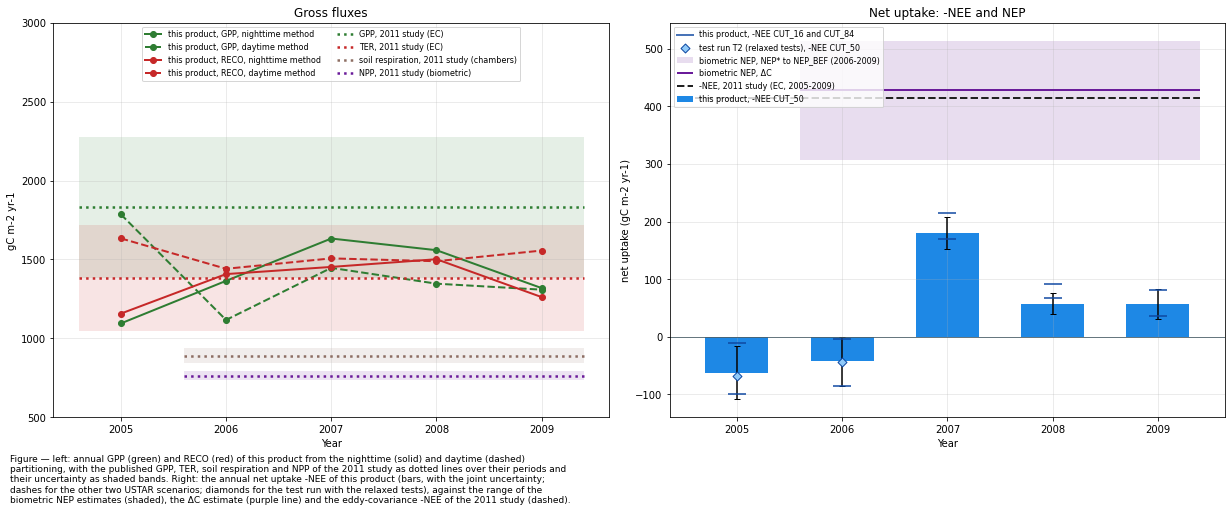

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(17, 7), dpi=72, layout="constrained")
_y = annual75.index.to_numpy()
ax = axs[0]
for _k, _c, _ls, _lab in (('GPP_NT', COLORS['GPP'], '-', "GPP, nighttime method"),
                          ('GPP_DT', COLORS['GPP'], '--', "GPP, daytime method"),
                          ('RECO_NT', COLORS['RECO'], '-', "RECO, nighttime method"),
                          ('RECO_DT', COLORS['RECO'], '--', "RECO, daytime method")):
    ax.plot(_y, annual75[_k], color=_c, ls=_ls, marker='o', lw=2, label=f"this product, {_lab}")
for _key, _c, _lab in (('GPP_EC', COLORS['GPP'], "GPP, 2011 study (EC)"),
                       ('TER_EC', COLORS['RECO'], "TER, 2011 study (EC)"),
                       ('SR', COLORS['SR'], "soil respiration, 2011 study (chambers)"),
                       ('NPP', COLORS['NEP'], "NPP, 2011 study (biometric)")):
    _v, _lo, _hi = pub(_key)
    _x0, _x1 = published.loc[_key, 'first'] - 0.4, published.loc[_key, 'last'] + 0.4
    ax.fill_between([_x0, _x1], _lo, _hi, color=_c, alpha=0.12, lw=0)
    ax.hlines(_v, _x0, _x1, color=_c, lw=2.5, ls=':', label=_lab)
ax.set_ylabel(units_sum)
ax.set_title("Gross fluxes")
ax.set_ylim(500, 3000)
ax.legend(fontsize=8, loc='upper center', ncol=2)
ax = axs[1]
ax.bar(_y, -annual75['NEE CUT_50'], color=COLORS['IRGA75'], width=0.6,
       yerr=annual75['NEE joint unc.'], capsize=3, label="this product, -NEE CUT_50")
ax.scatter(_y, -annual75['NEE CUT_16'], marker='_', s=300, color='#0D47A1', zorder=5,
           label="this product, -NEE CUT_16 and CUT_84")
ax.scatter(_y, -annual75['NEE CUT_84'], marker='_', s=300, color='#0D47A1', zorder=5)
if HAS_T2:
    ax.scatter(_y, -annual75['NEE CUT_50, T2'], marker='D', s=40, color=COLORS['T2'],
               edgecolor='#0D47A1', zorder=6, label="test run T2 (relaxed tests), -NEE CUT_50")
_nep = published.loc[NEP_KEYS]
ax.fill_between([2005.6, 2009.4], _nep['value'].min(), _nep['value'].max(), color=COLORS['NEP'],
                alpha=0.15, lw=0, label="biometric NEP, NEP* to NEP_BEF (2006-2009)")
ax.hlines(published.loc['NEP_DC', 'value'], 2005.6, 2009.4, color=COLORS['NEP'], lw=2,
          label="biometric NEP, ΔC")
ax.hlines(-published.loc['NEE_EC', 'value'], 2004.6, 2009.4, color=COLORS['study2011'], lw=2,
          ls='--', label="-NEE, 2011 study (EC, 2005-2009)")
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_ylabel(f"net uptake ({units_sum})")
ax.set_title("Net uptake: -NEE and NEP")
ax.legend(fontsize=8, loc='upper left')
for ax in axs:
    ax.set_xticks(_y)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)
figcap(fig, "left: annual GPP (green) and RECO (red) of this product from the nighttime (solid) and "
            "daytime (dashed) partitioning, with the published GPP, TER, soil respiration and NPP of the "
            "2011 study as dotted lines over their periods and their uncertainty as shaded bands. Right: "
            "the annual net uptake -NEE of this product (bars, with the joint uncertainty; dashes for "
            "the other two USTAR scenarios; diamonds for the test run with the relaxed tests), against "
            "the range of the biometric NEP estimates (shaded), the ΔC estimate (purple line) and the "
            "eddy-covariance -NEE of the 2011 study (dashed).")
fig.show()

The gross fluxes of this product are close to the published `TER` and well below the published
`GPP` in most years. The net uptake lies far below the band of the biometric `NEP` in every year
and every scenario.

</br>

# 3. Checks against the independent estimates

Each check compares a mean of this product with a published value over the same years.

## Net uptake against biometric NEP

Over long enough periods, and without harvest, fire or lateral losses, `NEP` and `-NEE` measure
the same quantity (Etzold et al. 2011, p. 1290). The forest inventory covers 2005-2009; the
biometric fluxes are given as means of 2006-2009.

### 📋 Table: -NEE against the biometric NEP estimates

In [16]:
_m = means75.loc[f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
_rows = {}
for _k in ['-NEE CUT_16', '-NEE CUT_50', '-NEE CUT_84']:
    _rows[f"this product, {_k}"] = _m[_k]
if HAS_T2 and len(T2_SHIFT):
    # The relaxed tests are known for 2005 and 2006 only. Their largest effect per year is applied
    # to every year of the period, as a bound on how far they could move the mean.
    _rows["this product, -NEE CUT_50 with the largest effect of the relaxed tests"] = (
        _m['-NEE CUT_50'] - T2_SHIFT.min())
netup = pd.DataFrame({'-NEE or NEP': pd.Series(_rows)})
for _key in NEP_KEYS + ['NEE_EC_0609']:
    _v, _lo, _hi = pub(_key)
    _sign = -1 if _key.startswith('NEE') else 1
    netup.loc[f"2011 study, {published.loc[_key, 'quantity']}" + (" (as -NEE)" if _sign < 0 else ""),
              '-NEE or NEP'] = _sign * _v
_nep_lo, _nep_hi = published.loc['NEP_STAR', 'low'], published.loc['NEP_BEF', 'high']
netup['minus NEP*'] = netup['-NEE or NEP'] - published.loc['NEP_STAR', 'value']
netup['minus ΔC'] = netup['-NEE or NEP'] - published.loc['NEP_DC', 'value']
netup['within NEP* to NEP_BEF'] = [verdict(v, _nep_lo, _nep_hi) for v in netup['-NEE or NEP']]
display(styled(netup, caption=f"mean net uptake {FIG4_YEARS[0]}-{FIG4_YEARS[1]} in {units_sum}: -NEE of "
                              f"this product for the three USTAR scenarios, and the biometric NEP "
                              f"estimates and the eddy-covariance -NEE of the 2011 study. The last "
                              f"columns give the difference to NEP* (the lowest estimate) and to ΔC, "
                              f"and whether the value lies within the range spanned by NEP* and NEP_BEF "
                              f"({_nep_lo:.0f} to {_nep_hi:.0f}). The row with the relaxed tests "
                              f"applies their largest effect in 2005 and 2006 to all four years",
               fmt="{:.0f}", subset=['minus NEP*', 'minus ΔC'], cmap='RdBu', center=True))

Table — mean net uptake 2006-2009 in gC m-2 yr-1: -NEE of this product for the three USTAR
scenarios, and the biometric NEP estimates and the eddy-covariance -NEE of the 2011 study. The last
columns give the difference to NEP* (the lowest estimate) and to ΔC, and whether the value lies
within the range spanned by NEP* and NEP_BEF (296 to 525). The row with the relaxed tests applies
their largest effect in 2005 and 2006 to all four years



,-NEE or NEP,minus NEP*,minus ΔC,within NEP* to NEP_BEF
"this product, -NEE CUT_16",96,-211,-333,below
"this product, -NEE CUT_50",63,-244,-366,below
"this product, -NEE CUT_84",47,-260,-382,below
"this product, -NEE CUT_50 with the largest effect of the relaxed tests",62,-245,-367,below
"2011 study, NEP* (NPP - Rh)",307,0,-122,within
"2011 study, NEP as change in C pools (ΔC)",429,122,0,within
"2011 study, NEP_BM (pools 2009 minus 2006)",434,127,5,within
"2011 study, NEP_BEF (expansion factors)",514,207,85,within
"2011 study, NEE, eddy covariance (as -NEE)",435,128,6,within


The net uptake of this product lies several hundred gC m⁻² yr⁻¹ below the lowest biometric
estimate, for all three USTAR thresholds. The relaxed tests reduce the gap by less than a third.
The eddy-covariance `NEE` of the 2011 study, with the same instrument, lies within the biometric
range.

## Ecosystem respiration against soil respiration

Ecosystem respiration is soil respiration plus the respiration of stems, branches, leaves and
the understory above ground, so `RECO` must exceed `SR`. `RECO - SR` is an estimate of the
aboveground respiration, and `SR / RECO` the share of the soil. In the 2011 study that share is
about two thirds.

### 📋 Table: RECO against soil respiration

In [17]:
_m = means75.loc[f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
_sr, _sr_lo, _sr_hi = pub('SR')
resp = pd.DataFrame(index=['this product, RECO_NT', 'this product, RECO_DT', '2011 study, TER (EC)'])
resp['RECO or TER'] = [_m['RECO_NT'], _m['RECO_DT'], published.loc['TER_EC', 'value']]
resp['period'] = [f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"] * 2 + ['2005-2009']
resp['SR'] = _sr
resp['RECO - SR'] = resp['RECO or TER'] - _sr
resp['SR / RECO'] = _sr / resp['RECO or TER']
resp['RECO > SR'] = resp['RECO or TER'] > _sr_hi
resp['SR / RECO within the 2011 range'] = [verdict(v, *SR_TER_RANGE) for v in resp['SR / RECO']]
display(styled(resp, caption=f"mean ecosystem respiration of this product {FIG4_YEARS[0]}-{FIG4_YEARS[1]} "
                             f"from both partitionings, and the TER of the 2011 study, against their "
                             f"soil respiration of {_sr:.0f} ({_sr_lo:.0f}-{_sr_hi:.0f}) {units_sum}. "
                             f"RECO - SR is the aboveground respiration it implies. The range of SR / "
                             f"TER from the stated uncertainties of the study is {SR_TER_RANGE[0]:.2f} "
                             f"to {SR_TER_RANGE[1]:.2f}",
               fmt={'RECO or TER': "{:.0f}", 'SR': "{:.0f}", 'RECO - SR': "{:.0f}", 'SR / RECO': "{:.2f}"}))

Table — mean ecosystem respiration of this product 2006-2009 from both partitionings, and the TER of
the 2011 study, against their soil respiration of 890 (844-936) gC m-2 yr-1. RECO - SR is the
aboveground respiration it implies. The range of SR / TER from the stated uncertainties of the study
is 0.49 to 0.90



,RECO or TER,period,SR,RECO - SR,SR / RECO,RECO > SR,SR / RECO within the 2011 range
"this product, RECO_NT",1406,2006-2009,890,516,0.63,True,within
"this product, RECO_DT",1498,2006-2009,890,608,0.59,True,within
"2011 study, TER (EC)",1383,2005-2009,890,493,0.64,True,within


Both partitionings give a respiration above the soil respiration, with an aboveground part
somewhat larger than in the 2011 study and a soil share inside the range its uncertainties allow.
The respiration of this product is not too low to contain the measured soil respiration, and not so
high that the soil share becomes implausibly small.

## Gross uptake and the ratio of NPP to GPP

`GPP` is not measured; both partitionings model it from `NEE`. The biometric `NPP` gives an
independent lower bound, since `GPP = NPP + Ra` and the autotrophic respiration `Ra` is positive,
and, with a typical ratio of `NPP` to `GPP`, an independent estimate.

### 📋 Table: GPP against the published and the implied GPP

In [18]:
_m5 = means75.loc[f"{YEARS75[0]}-{YEARS75[1]}"]
_m4 = means75.loc[f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
_g, _g_lo, _g_hi = pub('GPP_EC')
_npp = published.loc['NPP', 'value']
gpp = pd.DataFrame(index=['this product, GPP_NT', 'this product, GPP_DT'])
gpp['GPP 2005-2009'] = [_m5['GPP_NT'], _m5['GPP_DT']]
gpp['minus GPP of the 2011 study'] = gpp['GPP 2005-2009'] - _g
gpp['within its uncertainty'] = [verdict(v, _g_lo, _g_hi) for v in gpp['GPP 2005-2009']]
gpp[f"GPP {FIG4_YEARS[0]}-{FIG4_YEARS[1]}"] = [_m4['GPP_NT'], _m4['GPP_DT']]
gpp['NPP / GPP'] = _npp / gpp[f"GPP {FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
gpp['minus GPP implied by NPP'] = gpp[f"GPP {FIG4_YEARS[0]}-{FIG4_YEARS[1]}"] - derived[
    'GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)']
gpp['RECO / GPP'] = [_m5['RECO_NT'] / _m5['GPP_NT'], _m5['RECO_DT'] / _m5['GPP_DT']]
gpp.loc['2011 study (EC)', ['GPP 2005-2009', 'NPP / GPP', 'RECO / GPP']] = [
    _g, _npp / _g, published.loc['TER_EC', 'value'] / _g]
display(styled(gpp, caption=f"mean GPP of this product from both partitionings against the GPP of the "
                            f"2011 study, {_g:.0f} ({_g_lo:.0f}-{_g_hi:.0f}) {units_sum} over "
                            f"{YEARS75[0]}-{YEARS75[1]}, and against the GPP implied by their NPP of "
                            f"{_npp:.0f} and a forest NPP/GPP of {CUE_FOREST[0]} ± {CUE_FOREST[1]} "
                            f"(Waring et al. 1998): "
                            f"{derived['GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)']:.0f} "
                            f"({GPP_BIO_RANGE[0]:.0f}-{GPP_BIO_RANGE[1]:.0f}) over {FIG4_YEARS[0]}-"
                            f"{FIG4_YEARS[1]}. NPP / GPP is the ratio this product implies. The study "
                            f"quotes a TER / GPP of {TER_GPP_EUROPE} as the reference for European "
                            f"forests",
               fmt={'GPP 2005-2009': "{:.0f}", 'minus GPP of the 2011 study': "{:.0f}",
                    f"GPP {FIG4_YEARS[0]}-{FIG4_YEARS[1]}": "{:.0f}", 'NPP / GPP': "{:.2f}",
                    'minus GPP implied by NPP': "{:.0f}", 'RECO / GPP': "{:.2f}"}))

Table — mean GPP of this product from both partitionings against the GPP of the 2011 study, 1830
(1382-2278) gC m-2 yr-1 over 2005-2009, and against the GPP implied by their NPP of 763 and a forest
NPP/GPP of 0.47 ± 0.04 (Waring et al. 1998): 1623 (1439-1842) over 2006-2009. NPP / GPP is the ratio
this product implies. The study quotes a TER / GPP of 0.74 as the reference for European forests



,GPP 2005-2009,minus GPP of the 2011 study,within its uncertainty,GPP 2006-2009,NPP / GPP,minus GPP implied by NPP,RECO / GPP
"this product, GPP_NT",1394,-436,within,1468,0.52,-155,0.97
"this product, GPP_DT",1401,-429,within,1304,0.58,-319,1.09
2011 study (EC),1830,-,-,-,0.42,-,0.76


`GPP` of this product lies well below the `GPP` of the 2011 study and below the `GPP` that the
biometric `NPP` implies with a typical carbon-use efficiency. Its `GPP` would require more than
half of the gross uptake to be retained as `NPP`, and a ratio of `RECO` to `GPP` at or above 1,
against about three quarters for European forests.

## Heterotrophic respiration implied by NEE

`NEP = NPP - Rh`. If the net uptake of this product were the true `NEP`, the heterotrophic
respiration would be `Rh = NPP + NEE`. This can be compared with the two independent estimates of
`Rh` and with soil respiration, which contains `Rh` and is therefore an upper bound for it.

### 📋 Table: implied heterotrophic respiration

In [19]:
_npp = published.loc['NPP', 'value']
_m4 = means75.loc[f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
rh = pd.DataFrame({'Rh': {f"implied by this product, NPP + NEE {k}": _npp - _m4[f"-NEE {k}"]
                          for k in SCENARIOS}})
for _key, _lab in (('RH_CH', "2011 study, chambers (2007-2008)"),
                   ('RH_MOD', "2011 study, Yasso07 (2006-2009)"),
                   ('SR', "2011 study, total soil respiration (upper bound)")):
    rh.loc[_lab, 'Rh'] = published.loc[_key, 'value']
    rh.loc[_lab, 'low'], rh.loc[_lab, 'high'] = published.loc[_key, ['low', 'high']]
rh['Rh / SR'] = rh['Rh'] / published.loc['SR', 'value']
display(styled(rh, caption=f"heterotrophic respiration in {units_sum}: as implied by the biometric NPP "
                           f"({_npp:.0f}) and the mean NEE of this product {FIG4_YEARS[0]}-{FIG4_YEARS[1]} "
                           f"for the three USTAR scenarios, and the independent estimates of the 2011 "
                           f"study with their bounds. Rh / SR is the share of soil respiration it would "
                           f"take",
               fmt={'Rh': "{:.0f}", 'low': "{:.0f}", 'high': "{:.0f}", 'Rh / SR': "{:.2f}"}))

Table — heterotrophic respiration in gC m-2 yr-1: as implied by the biometric NPP (763) and the mean
NEE of this product 2006-2009 for the three USTAR scenarios, and the independent estimates of the
2011 study with their bounds. Rh / SR is the share of soil respiration it would take



,Rh,low,high,Rh / SR
"implied by this product, NPP + NEE CUT_16",667,-,-,0.75
"implied by this product, NPP + NEE CUT_50",700,-,-,0.79
"implied by this product, NPP + NEE CUT_84",716,-,-,0.80
"2011 study, chambers (2007-2008)",507,459,555,0.57
"2011 study, Yasso07 (2006-2009)",455,428,482,0.51
"2011 study, total soil respiration (upper bound)",890,844,936,1.00


To balance the biometric `NPP`, the heterotrophic respiration would have to be far above both
independent estimates and close to the whole soil respiration, leaving almost nothing for the
roots. The wood increment of trunks and branches from the inventories, and the stem growth from
the dendrometers, each exceed the net uptake of this product by several hundred gC m⁻² yr⁻¹. For a
net uptake near zero the soil and the litter would have to lose about as much carbon as the wood
gains, while the soil model of the study gives a small gain.

## Where the difference to the 2011 study lies

The `NEE` of this product and of the 2011 study differ by the difference in `RECO` minus the
difference in `GPP`. The 2011 values are means of 2005-2009, so this product is averaged over the
same years. Their `GPP` and `TER` do not exactly add up to their `NEE`, so the two parts do not add
up exactly to the difference in `NEE`.

### 📋 Table: difference in NEE split into RECO and GPP

In [20]:
_m5 = means75.loc[f"{YEARS75[0]}-{YEARS75[1]}"]
_ter, _gpp, _nee = (published.loc[k, 'value'] for k in ('TER_EC', 'GPP_EC', 'NEE_EC'))
split = pd.DataFrame(index=['nighttime partitioning', 'daytime partitioning'])
split['NEE, this product minus 2011'] = _m5['NEE CUT_50'] - _nee
split['from RECO (RECO minus TER)'] = [_m5['RECO_NT'] - _ter, _m5['RECO_DT'] - _ter]
split['from GPP (2011 GPP minus GPP)'] = [_gpp - _m5['GPP_NT'], _gpp - _m5['GPP_DT']]
_parts = split['from RECO (RECO minus TER)'] + split['from GPP (2011 GPP minus GPP)']
split['share from GPP (%)'] = split['from GPP (2011 GPP minus GPP)'] / _parts * 100
display(styled(split, caption=f"the difference in mean NEE {YEARS75[0]}-{YEARS75[1]} between this product "
                              f"(CUT_50) and the 2011 study in {units_sum}, and its two parts: the higher "
                              f"respiration and the lower GPP of this product. The share from GPP is that "
                              f"of the sum of the two parts",
               fmt={c: "{:.0f}" for c in split.columns}))

Table — the difference in mean NEE 2005-2009 between this product (CUT_50) and the 2011 study in gC
m-2 yr-1, and its two parts: the higher respiration and the lower GPP of this product. The share
from GPP is that of the sum of the two parts



,"NEE, this product minus 2011",from RECO (RECO minus TER),from GPP (2011 GPP minus GPP),share from GPP (%)
nighttime partitioning,377,-27,436,107
daytime partitioning,377,142,429,75


Most of the difference to the 2011 study comes from `GPP`: the respiration of the two products is
similar, the gross uptake is not. The partitioning assigns a correction applied by day to `GPP`,
so this points to the daytime flux, where the self-heating correction of this product is much
larger than the one used in 2011 (comparison notebook).

## 📊 Plot: carbon budget of 2006-2009

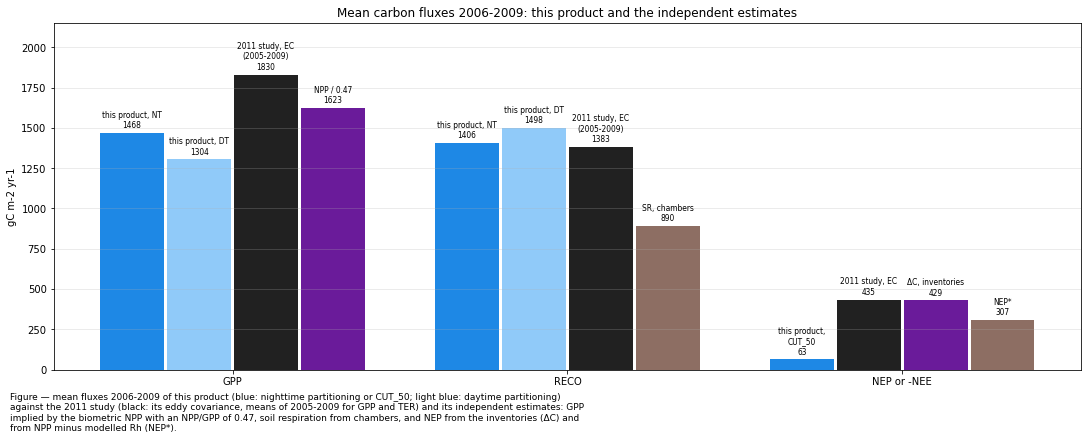

In [21]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
_m4 = means75.loc[f"{FIG4_YEARS[0]}-{FIG4_YEARS[1]}"]
_bars = [
    ("GPP", [('this product, NT', _m4['GPP_NT'], COLORS['IRGA75']),
             ('this product, DT', _m4['GPP_DT'], COLORS['T2']),
             ('2011 study, EC (2005-2009)', published.loc['GPP_EC', 'value'], COLORS['study2011']),
             ('NPP / 0.47', derived['GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)'], COLORS['NEP'])]),
    ("RECO", [('this product, NT', _m4['RECO_NT'], COLORS['IRGA75']),
              ('this product, DT', _m4['RECO_DT'], COLORS['T2']),
              ('2011 study, EC (2005-2009)', published.loc['TER_EC', 'value'], COLORS['study2011']),
              ('SR, chambers', published.loc['SR', 'value'], COLORS['SR'])]),
    ("NEP or -NEE", [('this product, CUT_50', _m4['-NEE CUT_50'], COLORS['IRGA75']),
                     ('2011 study, EC', -published.loc['NEE_EC_0609', 'value'], COLORS['study2011']),
                     ('ΔC, inventories', published.loc['NEP_DC', 'value'], COLORS['NEP']),
                     ('NEP*', published.loc['NEP_STAR', 'value'], COLORS['SR'])]),
]
_w = 0.2
for i, (_grp, _items) in enumerate(_bars):
    for j, (_lab, _v, _c) in enumerate(_items):
        ax.bar(i + (j - 1.5) * _w, _v, width=_w * 0.95, color=_c)
        ax.text(i + (j - 1.5) * _w, _v + 20 if _v >= 0 else _v - 20,
                textwrap.fill(_lab, 16) + f"\n{_v:.0f}", ha='center',
                va='bottom' if _v >= 0 else 'top', fontsize=7.5)
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xticks(range(len(_bars)))
ax.set_xticklabels([b[0] for b in _bars])
ax.set_ylabel(units_sum)
ax.set_title(f"Mean carbon fluxes {FIG4_YEARS[0]}-{FIG4_YEARS[1]}: this product and the independent estimates")
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)
figcap(fig, f"mean fluxes {FIG4_YEARS[0]}-{FIG4_YEARS[1]} of this product (blue: nighttime partitioning "
            f"or CUT_50; light blue: daytime partitioning) against the 2011 study (black: its eddy "
            f"covariance, means of 2005-2009 for GPP and TER) and its independent estimates: GPP implied "
            f"by the biometric NPP with an NPP/GPP of {CUE_FOREST[0]}, soil respiration from chambers, "
            f"and NEP from the inventories (ΔC) and from NPP minus modelled Rh (NEP*).")
fig.show()

</br>

# 4. Temperature response of soil respiration and nighttime NEE

Fig. 4 of the 2011 study shows soil respiration against soil temperature for 2006-2009, with
Lloyd-Taylor curves fitted per year. The curves were read from the figure (see *Settings* for the
method and the accuracy) and fitted here with the same function as the nighttime partitioning of
this product (`T0 = -46.02 °C`), with a reference temperature of 10 °C.

Nighttime `NEE` is ecosystem respiration. At the same soil temperature it must exceed soil
respiration. The measured nighttime `NEE` of this product (`CUT_50`, measured records only) is
compared with the curves in bins of 2 °C of soil temperature at 0.05 m, for the years of the
figure and for the LI-7200 years. The soil depth of the study is not stated; 0.05 m is assumed.

## 📋 Table: Lloyd-Taylor parameters of soil respiration and nighttime NEE

In [22]:
_rows = {}
for _name, _curves in FIG4.items():
    _r, _e, _rse, _ese, _ = fit_lloyd_taylor(FIG4_T, _curves['central'])
    _rows[f"2011 study, {_name} (Fig. 4, central curve)"] = {
        'Rref at 10 °C': _r, 'Rref SE': _rse, 'E0 (K)': _e, 'E0 SE': _ese, 'Q10 5-15 °C': q10(_e),
        'Rref published': SR_RREF[_name], 'records': np.nan}
for _lab, _d, _yrs in (('this product, IRGA75 nights', d75, FIG4_YEARS),
                       ('this product, IRGA72 nights', d72, YEARS72)):
    _n = _d.loc[str(_yrs[0]):str(_yrs[1])]
    _n = _n[_n['night'] & _n['meas'] & _n[TS].notna()]
    _r, _e, _rse, _ese, _cnt = fit_lloyd_taylor(_n[TS], _n[varname_meas])
    _rows[f"{_lab}, {_yrs[0]}-{_yrs[1]}"] = {'Rref at 10 °C': _r, 'Rref SE': _rse, 'E0 (K)': _e,
                                             'E0 SE': _ese, 'Q10 5-15 °C': q10(_e),
                                             'Rref published': np.nan, 'records': _cnt}
lt_params = pd.DataFrame(_rows).T
display(styled(lt_params, caption=f"Lloyd-Taylor fits against soil temperature (T0 {T0_LT} °C, reference "
                                  f"temperature {TREF_SOIL:.0f} °C): soil respiration of the automated and "
                                  f"the manual chambers, fitted to the central curve read from Fig. 4, with "
                                  f"the reference respiration the study gives for 2008-2009 (p. 1299); and "
                                  f"the measured nighttime NEE of this product against soil temperature at "
                                  f"0.05 m, fitted to the half-hours. Rref is in {units}. The SE of the "
                                  f"curve fits reflects only the scatter of the readings about the function",
               fmt={'Rref at 10 °C': "{:.2f}", 'Rref SE': "{:.2f}", 'E0 (K)': "{:.0f}", 'E0 SE': "{:.0f}",
                    'Q10 5-15 °C': "{:.2f}", 'Rref published': "{:.2f}", 'records': "{:,.0f}"}))

Table — Lloyd-Taylor fits against soil temperature (T0 -46.02 °C, reference temperature 10 °C): soil
respiration of the automated and the manual chambers, fitted to the central curve read from Fig. 4,
with the reference respiration the study gives for 2008-2009 (p. 1299); and the measured nighttime
NEE of this product against soil temperature at 0.05 m, fitted to the half-hours. Rref is in µmol
m-2 s-1. The SE of the curve fits reflects only the scatter of the readings about the function



,Rref at 10 °C,Rref SE,E0 (K),E0 SE,Q10 5-15 °C,Rref published,records
"2011 study, SR automated (Fig. 4, central curve)",1.97,0.02,352,7,3.09,1.91,-
"2011 study, SR manual (Fig. 4, central curve)",2.35,0.02,345,5,3.03,2.22,-
"this product, IRGA75 nights, 2006-2009",3.91,0.06,142,8,1.58,-,"9,734"
"this product, IRGA72 nights, 2016-2025",3.91,0.02,154,4,1.64,-,"32,308"


The reference respiration fitted to the curves read from the figure is within about 0.1 µmol m⁻²
s⁻¹ of the values the study gives for 2008-2009, which supports the reading and the reference
temperature of 10 °C. The temperature sensitivity of soil respiration is far higher than that of
the nighttime `NEE` of either analyser. Nighttime `NEE` at 10 °C soil temperature is well above
soil respiration in both analyser periods.

## 📋 Table: nighttime NEE and soil respiration by soil temperature

In [23]:
_edges = [t - TS_BIN_HALFWIDTH for t in FIG4_T] + [FIG4_T[-1] + TS_BIN_HALFWIDTH]


def night_bins(d, years):
    """Measured nighttime NEE and modelled RECO_NT per soil-temperature bin centred on FIG4_T."""
    n = d.loc[str(years[0]):str(years[1])]
    n = n[n['night'] & n[TS].notna()]
    b = pd.cut(n[TS], _edges, labels=FIG4_T)
    m = n[n['meas']]
    bm = pd.cut(m[TS], _edges, labels=FIG4_T)
    return pd.DataFrame({
        'NEE measured, mean': m[varname_meas].groupby(bm, observed=False).mean(),
        'NEE measured, median': m[varname_meas].groupby(bm, observed=False).median(),
        'records': m[varname_meas].groupby(bm, observed=False).size(),
        'RECO_NT, all nights': n[PARTITIONING['RECO_NT']].groupby(b, observed=False).mean(),
    })


_b75 = night_bins(d75, FIG4_YEARS)
_b72 = night_bins(d72, YEARS72)
tbins = pd.concat({f"IRGA75 {FIG4_YEARS[0]}-{FIG4_YEARS[1]}": _b75,
                   f"IRGA72 {YEARS72[0]}-{YEARS72[1]}": _b72}, axis=1)
for _name, _curves in FIG4.items():
    tbins[('2011 study', f"{_name} (Fig. 4)")] = _curves['central']
_srm = np.array(FIG4['SR manual']['central'])
for _era in (f"IRGA75 {FIG4_YEARS[0]}-{FIG4_YEARS[1]}", f"IRGA72 {YEARS72[0]}-{YEARS72[1]}"):
    tbins[(_era, 'SR manual / NEE mean')] = _srm / tbins[(_era, 'NEE measured, mean')].to_numpy()
tbins.index.name = 'TS 0.05 m (°C)'
_fmt = {c: ("{:,.0f}" if c[1] == 'records' else "{:.2f}") for c in tbins.columns}
display(styled(tbins, caption=f"measured nighttime NEE of this product (CUT_50, NIGHTTIME flag, measured "
                              f"records) and the nighttime partitioning RECO_NT over all nights, per "
                              f"bin of ±{TS_BIN_HALFWIDTH:.0f} °C of soil temperature at 0.05 m, in {units}; "
                              f"the soil respiration of the central curves of Fig. 4 at the bin centre; and "
                              f"the share of nighttime NEE that the manual-chamber soil respiration makes up",
               fmt=_fmt))

Table — measured nighttime NEE of this product (CUT_50, NIGHTTIME flag, measured records) and the
nighttime partitioning RECO_NT over all nights, per bin of ±1 °C of soil temperature at 0.05 m, in
µmol m-2 s-1; the soil respiration of the central curves of Fig. 4 at the bin centre; and the share
of nighttime NEE that the manual-chamber soil respiration makes up



## 📊 Plot: soil respiration and nighttime NEE against soil temperature

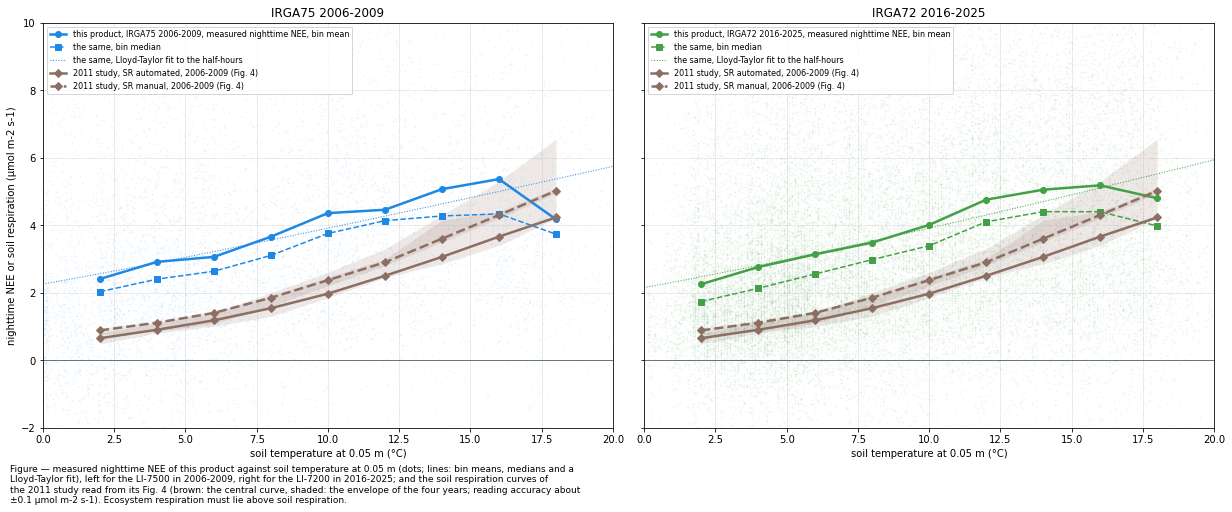

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(17, 7), dpi=72, layout="constrained", sharey=True)
_tt = np.linspace(0, 20, 101)
for ax, (_lab, _d, _yrs, _c) in zip(axs, (('IRGA75', d75, FIG4_YEARS, COLORS['IRGA75']),
                                           ('IRGA72', d72, YEARS72, COLORS['IRGA72']))):
    _n = _d.loc[str(_yrs[0]):str(_yrs[1])]
    _n = _n[_n['night'] & _n['meas'] & _n[TS].notna()]
    ax.scatter(_n[TS], _n[varname_meas], s=3, color=_c, alpha=0.08, lw=0)
    _bb = night_bins(_d, _yrs)
    ax.plot(_bb.index.astype(float), _bb['NEE measured, mean'], color=_c, marker='o', lw=2.5,
            label=f"this product, {_lab} {_yrs[0]}-{_yrs[1]}, measured nighttime NEE, bin mean")
    ax.plot(_bb.index.astype(float), _bb['NEE measured, median'], color=_c, marker='s', lw=1.5, ls='--',
            label="the same, bin median")
    _p = lt_params.loc[f"this product, {_lab} nights, {_yrs[0]}-{_yrs[1]}"]
    ax.plot(_tt, lloyd_taylor(_tt, _p['Rref at 10 °C'], _p['E0 (K)']), color=_c, lw=1, ls=':',
            label="the same, Lloyd-Taylor fit to the half-hours")
    for _name, _ls in (('SR automated', '-'), ('SR manual', '--')):
        _cv = FIG4[_name]
        ax.fill_between(FIG4_T, _cv['low'], _cv['high'], color=COLORS['SR'], alpha=0.15, lw=0)
        ax.plot(FIG4_T, _cv['central'], color=COLORS['SR'], ls=_ls, lw=2.5, marker='D', ms=5,
                label=f"2011 study, {_name}, 2006-2009 (Fig. 4)")
    ax.set_ylim(-2, 10)
    ax.set_xlim(0, 20)
    ax.axhline(0, color='#455A64', lw=0.8)
    ax.set_xlabel("soil temperature at 0.05 m (°C)")
    ax.set_title(f"{_lab} {_yrs[0]}-{_yrs[1]}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')
axs[0].set_ylabel(f"nighttime NEE or soil respiration ({units})")
figcap(fig, f"measured nighttime NEE of this product against soil temperature at 0.05 m (dots; lines: bin "
            f"means, medians and a Lloyd-Taylor fit), left for the LI-7500 in {FIG4_YEARS[0]}-"
            f"{FIG4_YEARS[1]}, right for the LI-7200 in {YEARS72[0]}-{YEARS72[1]}; and the soil "
            f"respiration curves of the 2011 study read from its Fig. 4 (brown: the central curve, "
            f"shaded: the envelope of the four years; reading accuracy about ±{FIG4_ACCURACY} {units}). "
            f"Ecosystem respiration must lie above soil respiration.")
fig.show()

The two analyser periods show the same pattern. Below about 10 °C soil temperature the nighttime
`NEE` is two to three times the soil respiration; towards 16-18 °C the two converge, and in the
warmest bin the soil respiration of the manual chambers reaches or exceeds the bin mean of the
nighttime `NEE`. Ecosystem respiration cannot be lower than soil respiration, so the warm summer
nights of both analysers are, if anything, too low, as is common for nighttime eddy covariance on a
slope. On the cold nights the excess over soil respiration is large in both periods; how much of
it is aboveground respiration of a mostly leafless forest cannot be decided from these data. At
the same soil temperature the cold nights of the LI-7500 are somewhat higher than those of the
LI-7200. The table below gives what this difference amounts to over a year.

## 📋 Table: what the difference in nighttime NEE between the analysers amounts to per year

In [25]:
# The measured nighttime NEE of the LI-7500 (2005-2009) minus that of the LI-7200 (2016-2025) at the
# same soil temperature, applied to all nights of 2005-2009 in that bin, measured or gap-filled.
_b75_all = night_bins(d75, YEARS75)
_n75 = d75[d75['night'] & d75[TS].notna()]
_count = pd.cut(_n75[TS], _edges, labels=FIG4_T).value_counts().reindex(FIG4_T)
_nyears = YEARS75[1] - YEARS75[0] + 1
nightdiff = pd.DataFrame({
    f"IRGA75 {YEARS75[0]}-{YEARS75[1]}, mean": _b75_all['NEE measured, mean'],
    f"IRGA72 {YEARS72[0]}-{YEARS72[1]}, mean": _b72['NEE measured, mean'],
})
nightdiff['IRGA75 minus IRGA72'] = nightdiff.iloc[:, 0] - nightdiff.iloc[:, 1]
nightdiff['night half-hours per year'] = _count.to_numpy() / _nyears
nightdiff['amount per year (gC m-2)'] = (nightdiff['IRGA75 minus IRGA72']
                                         * nightdiff['night half-hours per year'] * UMOL_TO_GC)
nightdiff.index.name = 'TS 0.05 m (°C)'
NIGHT_SHARE_BINNED = _count.sum() / d75['night'].sum()
NIGHTDIFF_SUM = nightdiff['amount per year (gC m-2)'].sum()
NIGHTDIFF_COLD = nightdiff.loc[[t for t in FIG4_T if t <= 8], 'amount per year (gC m-2)'].sum()
display(styled(nightdiff, caption=f"mean measured nighttime NEE per bin of soil temperature at 0.05 m in "
                                  f"{units}, of the LI-7500 over {YEARS75[0]}-{YEARS75[1]} and of the LI-7200 "
                                  f"over {YEARS72[0]}-{YEARS72[1]}, their difference, the number of night "
                                  f"half-hours per year of {YEARS75[0]}-{YEARS75[1]} in each bin (measured and "
                                  f"gap-filled), and what the difference amounts to over these half-hours. "
                                  f"The bins hold {NIGHT_SHARE_BINNED * 100:.0f} % of the nights; the rest "
                                  f"have no measured soil temperature or one outside 1-19 °C",
               fmt={c: ("{:.2f}" if 'mean' in c or 'minus' in c else "{:.0f}") for c in nightdiff.columns},
               subset=['amount per year (gC m-2)'], cmap='RdBu_r', center=True))
print(f"Sum over all bins: {NIGHTDIFF_SUM:+.0f} gC m-2 per year; bins up to 8 degC: {NIGHTDIFF_COLD:+.0f}")

Table — mean measured nighttime NEE per bin of soil temperature at 0.05 m in µmol m-2 s-1, of the
LI-7500 over 2005-2009 and of the LI-7200 over 2016-2025, their difference, the number of night
half-hours per year of 2005-2009 in each bin (measured and gap-filled), and what the difference
amounts to over these half-hours. The bins hold 75 % of the nights; the rest have no measured soil
temperature or one outside 1-19 °C



,"IRGA75 2005-2009, mean","IRGA72 2016-2025, mean",IRGA75 minus IRGA72,night half-hours per year,amount per year (gC m-2)
TS 0.05 m (°C),,,,,
2,2.30,2.25,0.05,1160,1
4,2.85,2.76,0.09,967,2
6,2.96,3.14,-0.18,799,-3
8,3.48,3.48,-0.00,721,-0
10,4.27,4.01,0.26,766,4
12,4.48,4.76,-0.28,699,-4
14,5.00,5.05,-0.05,668,-1
16,5.40,5.18,0.22,489,2
18,4.11,4.80,-0.69,294,-4


Sum over all bins: -3 gC m-2 per year; bins up to 8 degC: -0


If the LI-7500 nights had the same response to soil temperature as the LI-7200 nights, the annual
`NEE` of 2005-2009 would change by the sum in the last column. This is an approximation: it treats
the gap-filled nights like the measured ones and attributes any change of the forest between the
two decades to the analyser. It is small against the difference to the biometric `NEP`.

## 📋 Table: temperature sensitivity of the nighttime partitioning per year

In [26]:
_e0 = pd.concat([d75[E0_NT].groupby(d75.index.year).first(),
                 d72[E0_NT].groupby(d72.index.year).first()]).to_frame('E0_NT (K)')
_e0['Q10 5-15 °C'] = q10(_e0['E0_NT (K)'])
_e0['analyser'] = ['LI-7500' if y <= YEARS75[1] else 'LI-7200' for y in _e0.index]
_e0.index.name = 'YEAR'
display(styled(_e0, caption="the temperature sensitivity E0 of the nighttime partitioning of this product, "
                            "one per year, fitted against air temperature at 47 m with a reference "
                            "temperature of 15 °C, and the Q10 it implies. Air temperature varies more "
                            "than soil temperature, so these values are lower than those against soil "
                            "temperature in the table above and not directly comparable with the soil "
                            "respiration of the 2011 study",
               fmt={'E0_NT (K)': "{:.0f}", 'Q10 5-15 °C': "{:.2f}"}))

Table — the temperature sensitivity E0 of the nighttime partitioning of this product, one per year,
fitted against air temperature at 47 m with a reference temperature of 15 °C, and the Q10 it
implies. Air temperature varies more than soil temperature, so these values are lower than those
against soil temperature in the table above and not directly comparable with the soil respiration of
the 2011 study



,E0_NT (K),Q10 5-15 °C,analyser
YEAR,,,
2005,116,1.45,LI-7500
2006,117,1.46,LI-7500
2007,113,1.44,LI-7500
2008,107,1.41,LI-7500
2009,135,1.54,LI-7500
2016,54,1.19,LI-7200
2017,209,1.96,LI-7200
2018,92,1.34,LI-7200
2019,105,1.40,LI-7200


</br>

# 5. The LI-7200 years for reference

The same metrics for the LI-7200 years 2016-2025. The biometric values describe 2005-2009, a
decade earlier; forest growth, management and the drought years since then can change all of
them. The comparison shows whether the LI-7200 years are closer to the independent estimates than
the LI-7500 years, not whether they are correct.

## 📋 Table: annual sums 2016-2025

In [27]:
_a72 = annual72.copy()
_a72.loc['mean'] = _a72.mean()
_fmt = {c: "{:.0f}" for c in _a72.columns}
_fmt.update({c: "{:.1f}" for c in _a72.columns if '%' in c})
display(styled(_a72, caption=f"annual sums of the LI-7200 years in {units_sum}, as in the table of the "
                             f"LI-7500 years, with their mean",
               fmt=_fmt))

Table — annual sums of the LI-7200 years in gC m-2 yr-1, as in the table of the LI-7500 years, with
their mean



,NEE CUT_16,NEE CUT_50,NEE CUT_84,NEE joint unc.,GPP_NT,RECO_NT,GPP_DT,RECO_DT,measured (%),nights measured (%)
YEAR,,,,,,,,,,
2016,-174,-159,-95,41,1858,1699,1953,1673,35.3,29.5
2017,39,71,80,24,1478,1549,1732,1908,48.8,38.9
2018,-128,-110,-98,20,1429,1319,1719,1671,45.6,37.5
2019,-296,-292,-290,13,1666,1374,1766,1344,39.4,29.3
2020,-289,-267,-245,25,1547,1279,1779,1640,46.4,35.7
2021,-24,-22,2,19,1361,1339,1511,1635,45.3,36.0
2022,-36,-16,16,28,1490,1473,1561,1482,46.8,37.4
2023,-8,13,39,27,1480,1493,1627,1755,50.8,42.7
2024,-59,-43,-16,25,1637,1594,1732,1896,48.8,41.5


## 📋 Table: the checks for both analyser periods

In [28]:
def checks(annual, years):
    """The checks of section 3 for the mean of `years`."""
    m = our_means(annual, years)
    _npp, _sr = published.loc['NPP', 'value'], published.loc['SR', 'value']
    return pd.Series({
        '-NEE CUT_50': m['-NEE CUT_50'],
        '-NEE CUT_16 to CUT_84, lowest': m[['-NEE CUT_16', '-NEE CUT_50', '-NEE CUT_84']].min(),
        '-NEE CUT_16 to CUT_84, highest': m[['-NEE CUT_16', '-NEE CUT_50', '-NEE CUT_84']].max(),
        'GPP_NT': m['GPP_NT'], 'GPP_DT': m['GPP_DT'],
        'RECO_NT': m['RECO_NT'], 'RECO_DT': m['RECO_DT'],
        'RECO_NT - SR': m['RECO_NT'] - _sr, 'SR / RECO_NT': _sr / m['RECO_NT'],
        'NPP / GPP_NT': _npp / m['GPP_NT'], 'RECO_NT / GPP_NT': m['RECO_NT'] / m['GPP_NT'],
        'Rh implied, NPP + NEE CUT_50': _npp - m['-NEE CUT_50'],
    })


_ref = pd.Series({
    '-NEE CUT_50': f"NEP {published.loc['NEP_STAR', 'value']:.0f} (NEP*) to "
                   f"{published.loc['NEP_BEF', 'value']:.0f} (NEP_BEF), ΔC {published.loc['NEP_DC', 'value']:.0f}",
    'GPP_NT': f"{published.loc['GPP_EC', 'value']:.0f} ± {published.loc['GPP_EC', 'value'] - published.loc['GPP_EC', 'low']:.0f} (EC); "
              f"{derived['GPP implied by NPP and the forest NPP/GPP (gC m-2 yr-1)']:.0f} from NPP",
    'RECO_NT': f"TER {published.loc['TER_EC', 'value']:.0f} ± {published.loc['TER_EC', 'value'] - published.loc['TER_EC', 'low']:.0f} (EC)",
    'RECO_NT - SR': f"{derived['TER - SR, aboveground respiration (gC m-2 yr-1)']:.0f} (TER - SR)",
    'SR / RECO_NT': f"{derived['SR / TER (2011 study)']:.2f} ({SR_TER_RANGE[0]:.2f}-{SR_TER_RANGE[1]:.2f})",
    'NPP / GPP_NT': f"{derived['NPP / GPP (2011 study)']:.2f} (2011 study); {CUE_FOREST[0]} ± {CUE_FOREST[1]} (forests)",
    'RECO_NT / GPP_NT': f"{derived['TER / GPP (2011 study, EC)']:.2f} (2011 study); {TER_GPP_EUROPE} (European forests)",
    'Rh implied, NPP + NEE CUT_50': f"{published.loc['RH_CH', 'value']:.0f} (chambers), "
                                    f"{published.loc['RH_MOD', 'value']:.0f} (Yasso07); SR {published.loc['SR', 'value']:.0f} is the upper bound",
})
both = pd.DataFrame({f"IRGA75 {FIG4_YEARS[0]}-{FIG4_YEARS[1]}": checks(annual75, FIG4_YEARS),
                     f"IRGA75 {YEARS75[0]}-{YEARS75[1]}": checks(annual75, YEARS75),
                     f"IRGA72 {YEARS72[0]}-{YEARS72[1]}": checks(annual72, YEARS72)})
both['independent value (2006-2009 unless stated)'] = _ref.reindex(both.index).fillna("")
_num = [c for c in both.columns if c.startswith('IRGA')]
display(styled(both, caption=f"the checks of section 3 for the LI-7500 years (over the period of the "
                             f"biometric values and over that of the eddy covariance of the 2011 study) "
                             f"and for the LI-7200 years, in {units_sum} or as ratios. The independent "
                             f"values all describe 2005-2009 and do not cover the LI-7200 years",
               fmt="{:.2f}").format({c: (lambda v: f"{v:.2f}" if abs(v) < 5 else f"{v:.0f}") for c in _num}))

Table — the checks of section 3 for the LI-7500 years (over the period of the biometric values and
over that of the eddy covariance of the 2011 study) and for the LI-7200 years, in gC m-2 yr-1 or as
ratios. The independent values all describe 2005-2009 and do not cover the LI-7200 years



,IRGA75 2006-2009,IRGA75 2005-2009,IRGA72 2016-2025,independent value (2006-2009 unless stated)
-NEE CUT_50,63,38,117,"NEP 307 (NEP*) to 514 (NEP_BEF), ΔC 429"
"-NEE CUT_16 to CUT_84, lowest",47,18,92,
"-NEE CUT_16 to CUT_84, highest",96,75,135,
GPP_NT,1468,1394,1565,1830 ± 448 (EC); 1623 from NPP
GPP_DT,1304,1401,1731,
RECO_NT,1406,1356,1448,TER 1383 ± 338 (EC)
RECO_DT,1498,1525,1674,
RECO_NT - SR,516,466,558,493 (TER - SR)
SR / RECO_NT,0.63,0.66,0.61,0.64 (0.49-0.90)
NPP / GPP_NT,0.52,0.55,0.49,0.42 (2011 study); 0.47 ± 0.04 (forests)


The LI-7200 years have more `GPP` than the LI-7500 years and a similar `RECO` from the nighttime
method, so their net uptake is larger. Their ratios of `NPP` to `GPP` and of `RECO` to `GPP` are
closer to the values of the 2011 study, but the net uptake is still well below the biometric `NEP`
of 2006-2009. Whether this reflects a change
of the forest or a remaining bias cannot be decided without biometric data for the later years.

</br>

# 6. Other independent information

The site description and the references of this repository (`docs/Site_Info.md`,
`docs/References.md`, `docs/references.bib`) were searched for further independent carbon fluxes
of this forest. Paul-Limoges et al. (2017) and Shekhar et al. (2024) are cited there for the
species composition, the growing season and the dryness of the site, and the FP2022 dataset
(Hörtnagl et al. 2023) is an earlier eddy-covariance product of the same site. None of the
repository pages quotes an annual `NEP`, `NPP`, soil respiration or `GPP` from these sources, so no
further value is used here. A leaf area index of 4.1 ± 0.3 m² m⁻² in June 2006 (Swiss FluxNet
site page) is the only other quantity of the stand, and it carries no carbon flux.

</br>

# 7. Summary

The early years of this product are inconsistent with the independent estimates in their net
uptake, and the inconsistency lies in the gross uptake, not in the respiration:

- Annual `RECO` passes the checks: it exceeds soil respiration with a plausible soil share and is
  within the uncertainty of the `TER` of the 2011 study. Against soil temperature, the nighttime
  `NEE` of both analysers is flatter than the soil respiration of Fig. 4: far above it on cold
  nights, about equal to it on the warmest. The cold LI-7500 nights are somewhat higher than the
  LI-7200 nights at the same soil temperature, which accounts for a small part of the gap.
- `GPP` fails the checks: it is below the eddy-covariance `GPP` of the 2011 study by about its
  stated maximum error, below the `GPP` implied by the biometric `NPP`, and it implies a high ratio
  of `NPP` to `GPP` and a `RECO` that exceeds `GPP`.
- The net uptake therefore fails as well, by several hundred gC m⁻² yr⁻¹ against every biometric
  `NEP`, and it would require a heterotrophic respiration close to the whole soil respiration.

This points to the daytime flux of the LI-7500: the self-heating correction adds most by day, and
in the summers of 2005-2007 the daytime uptake of this product is low (comparison notebook).

**Caveats**

- **Period.** The biometric fluxes are means of 2006-2009 between inventories of 2005 and 2009,
  the chamber `Rh` covers 2007-2008 and the stem growth 2006-2007. The checks use the same years,
  but a biometric `NEP` over four years is not an annual value and carries the timing of growth and
  storage.
- **Footprint and plot.** The inventory covers 1.48 ha and the soil respiration 16 plots within
  the footprint, which is larger and spans a managed and an unmanaged part of the forest.
- **Biometric uncertainty.** The stated uncertainties of `NPP` and `NEP` are narrow, but they do not
  include the assumptions of the methods; the study notes that its estimates of `NEP` differ by
  about 127 gC m⁻² yr⁻¹ among themselves (p. 1302-1303), most of it from the belowground dynamics.
  Even the lowest estimate, `NEP*`, lies far above the net uptake of this product.
- **The eddy covariance of the 2011 study** used the same LI-7500. It is independent of the
  processing of this product, not of the instrument.
- **Partitioning.** `GPP` and `RECO` are modelled, not measured. The nighttime method fits on
  measured nights only, which for the LI-7500 are few and dry, and the daytime method is fitted to
  daytime `NEE` that carries the full self-heating correction. Where the two methods agree, they
  still share the same `NEE`.
- **Fig. 4** was read from a figure; the reading accuracy is about ±0.1 µmol m⁻² s⁻¹ for a single
  curve. The soil depth of its temperature is not stated, and 0.05 m is used here.
- **The run.** The `IRGA75` run shown may still use the stricter tests of negative nighttime
  values; the relaxed tests make the early years less positive, by far less than the gap to the
  biometric `NEP`.

</br>

# End of notebook

In [29]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-30 19:29:46
